# 05 Linear regression with temperature

We add the day-ahead temperature forecast from `04_temperature` to the linear regression from `03_linear`
and measure its effect. For a fair comparison, the models with and without temperature are trained and
evaluated on exactly the same hours: training from **April 2021** (when archived forecasts begin) to 2023,
validation 2024, excluding the archive gap.

## Aligning temperature and load

The two series describe different things, so we first decide which temperature belongs to which load hour.

- **Load.** The value labelled 09:00 is the *average* over the hour from 08:00 to 09:00. Labels mark the
  end of each interval, as set in `src/data.py`.
- **Temperature.** The value labelled 09:00 is the forecast temperature *at* 09:00, an instantaneous value.

Joining the series on their labels would pair the load hour 08:00–09:00 with the temperature at the end of
that hour only. Instead, we use the mean of the temperatures at 08:00 and at 09:00 as an approximation of
the average temperature during the hour:

$$
T(t) = \tfrac{1}{2}\bigl(T_{\mathrm{inst}}(t - 1\,\mathrm{h}) + T_{\mathrm{inst}}(t)\bigr).
$$

In the code, `shift(1)` moves the value of the previous hour into the current row. The difference to a
plain join is small, since temperature changes little within an hour, but the choice should be explicit.

**Expected:** 494 missing temperature values. An averaged value is missing as soon as one of its two
inputs is missing: the 492 hours of the archive gap, the first hour after the gap (its start value lies in
the gap) and the first row of the series (there is no earlier value).

In [1]:
import pandas as pd

# Hourly load in MW (labels mark the end of each hour, UTC), as in 03_linear
load = pd.read_parquet("../data/processed/load_2020_2025.parquet")["load"]
y = (load * 4 / 1000).resample("h", closed="right", label="right").mean()
y.name = "load_mw"

# Day-ahead temperature forecast (instantaneous values at each full hour, UTC)
temp_inst = pd.read_parquet("../data/processed/temp_forecast_2021_2025.parquet")["temp_forecast"]

# Mean temperature over the hour ending at each label: average of the values
# at the start and at the end of the hour
temp = ((temp_inst.shift(1) + temp_inst) / 2).rename("temp")

# Keep the hours for which both series have a row
df = pd.concat([y, temp], axis=1, join="inner")

# Print some information about the data
print("Load hours:", len(y))
print("Temperature hours:", len(temp))
print("Common hours:", len(df))
print("Missing temperature:", df["temp"].isna().sum())
print(df.index.min(), "to", df.index.max())

Load hours: 52608
Temperature hours: 41664
Common hours: 41664
Missing temperature: 494
2021-04-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00


All 41'664 hours of the temperature series have a matching load hour, and exactly 494 temperature values
are missing, as expected. The common period runs from 1 April 2021 to the end of 2025 (labels in UTC).
**The rows with missing temperature are dropped when the feature table is built.**

## Load versus temperature

A linear model learns one coefficient per feature, i.e. a constant change in load per degree. Whether a
single temperature column is adequate depends on the shape of the relation between load and temperature.
We plot daily means, since hourly values are dominated by the daily load profile, and separate working days
from weekends and holidays, whose load level is lower. Only the training years (April 2021 to 2023) are
used, so that any choice made from this plot does not depend on the validation year.

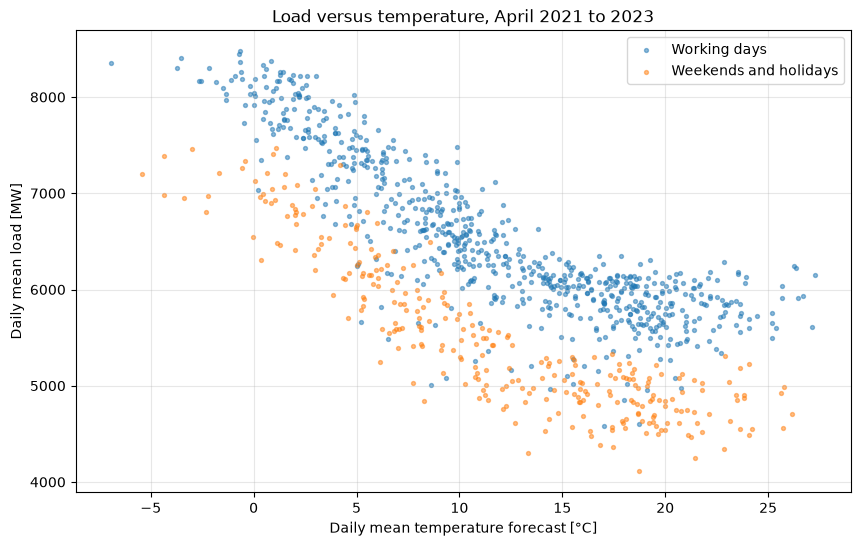

Days: 1003


In [ ]:
import matplotlib.pyplot as plt
import holidays

# Local date of each hour (start of the hour); labels mark the end of the hour
local = (df.index - pd.Timedelta(hours=1)).tz_convert("Europe/Zurich")
df["date"] = local.date
df["year"] = local.year

# Daily means of load and temperature on the training years
daily = df[df["year"] <= 2023].groupby("date")[["load_mw", "temp"]].mean().dropna()

# Days off: weekends and public holidays observed in all cantons
ch_holidays = holidays.CH(years=range(2021, 2024))
dates = pd.to_datetime(daily.index)
off = (dates.dayofweek >= 5) | dates.isin(pd.to_datetime(list(ch_holidays.keys())))

# Plot load versus temperature, distinguishing between working days and days off
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(daily.loc[~off, "temp"], daily.loc[~off, "load_mw"], s=8, alpha=0.5, label="Working days")
ax.scatter(daily.loc[off, "temp"], daily.loc[off, "load_mw"], s=8, alpha=0.5, label="Weekends and holidays")
ax.set_xlabel("Daily mean temperature forecast [°C]")
ax.set_ylabel("Daily mean load [MW]")
ax.set_title("Load versus temperature, April 2021 to 2023")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("Days:", len(daily))

## Feature table

The features are those of `03_linear` (hour, weekday, holiday share of the day and of the lag days, load
of the same hour on the previous day and one week earlier), plus the heating degrees `hdd`. The table is
built on the full load series, so that the lags at the start of April 2021 can use the load of March 2021.
Rows without a temperature forecast (before April 2021 and in the archive gap) have a missing `hdd` and are
dropped later for all models alike.

In [3]:
from collections import Counter

# Share of cantons in which each date is a public holiday, as in 03_linear
cantons = holidays.CH.subdivisions
counts = Counter()
for canton in cantons:
    for date in holidays.CH(subdiv=canton, years=range(2020, 2026)):
        counts[date] += 1
holiday_share = {date: n / len(cantons) for date, n in counts.items()}

# Threshold for the heating degrees, read from the scatter plot
T_REF = 15.0

# Local start time of each hour; labels mark the end of the hour
local_all = (y.index - pd.Timedelta(hours=1)).tz_convert("Europe/Zurich")
local_date = pd.Series(local_all.date, index=y.index)

X = pd.DataFrame(index=y.index)
X["hour"] = local_all.hour
X["weekday"] = local_all.dayofweek
X["holiday"] = local_date.map(holiday_share).fillna(0.0)
X["lag_24"] = y.shift(24)
X["lag_168"] = y.shift(168)
X["holiday_lag_24"] = X["holiday"].shift(24)
X["holiday_lag_168"] = X["holiday"].shift(168)

# Heating degrees: zero above the threshold, growing linearly below it
# (missing where no temperature forecast is available)
temp_all = temp.reindex(y.index)
X["hdd"] = (T_REF - temp_all).clip(lower=0)

# One indicator column per hour and weekday; hour 0 and Monday are the reference
X = pd.get_dummies(X, columns=["hour", "weekday"], drop_first=True, dtype=float)

print(X.shape)
print("Missing hdd:", X["hdd"].isna().sum())
X.loc["2021-04-01 01:00":"2021-04-01 05:00", ["lag_24", "lag_168", "holiday", "hdd"]]

(52608, 35)
Missing hdd: 11438


,lag_24,lag_168,holiday,hdd
2021-04-01 01:00:00+00:00,5382.118705,6027.974071,0.0,3.982107
2021-04-01 02:00:00+00:00,5328.111493,6027.827398,0.0,4.302342
2021-04-01 03:00:00+00:00,5337.680863,5999.340014,0.0,4.507701
2021-04-01 04:00:00+00:00,5788.765841,5975.465175,0.0,4.697014
2021-04-01 05:00:00+00:00,6628.543075,6449.832473,0.0,4.875901


The table has 35 columns, the 34 of `03_linear` plus `hdd`. The 11'438 missing values of `hdd` are the
10'944 hours before April 2021 and the 494 hours without a temperature forecast. The lags are available
from the first hour of April 2021, since they use the load of March 2021.

## Training on identical hours (from April 2021)

Both models are trained and evaluated on exactly the same rows: all hours with complete features, i.e.
from April 2021 and outside the archive gap. Training uses the years up to 2023, validation the year 2024.
The model without temperature uses all columns except `hdd`. The two baselines from `02_baseline` (same
hour one week earlier, and the mean of the same hour over the previous four weeks) are evaluated on the
same validation hours.

In [5]:
from sklearn.linear_model import LinearRegression


def mae(y_true, y_pred):
    # Mean absolute error, in the unit of y (MW)
    return (y_true - y_pred).abs().mean()


def mape(y_true, y_pred):
    # Mean absolute percentage error, in %
    return 100 * ((y_true - y_pred).abs() / y_true).mean()


# Local calendar year of each hour (start of the hour)
year = local_all.year

# Rows with all features available, including hdd: identical for all models
complete = X.notna().all(axis=1)
train = complete & (year <= 2023)
val = complete & (year == 2024)

cols_temp = list(X.columns)
cols_no_temp = [c for c in X.columns if c != "hdd"]

print("Training rows:", train.sum(), " Validation rows:", val.sum())

results = {}
predictions = {}

# Baselines: same hour one week earlier, and mean of the same hour over the previous four weeks
y_hat_1w = X["lag_168"]
y_hat_4w = pd.concat([y.shift(168 * k) for k in range(1, 5)], axis=1).mean(axis=1)
results["Baseline (four-week mean)"] = (mae(y[val], y_hat_4w[val]), mape(y[val], y_hat_4w[val]))
results["Baseline (one week)"] = (mae(y[val], y_hat_1w[val]), mape(y[val], y_hat_1w[val]))

# Linear models without and with temperature, fitted on the same training rows
for name, cols in [("Linear without temperature", cols_no_temp), ("Linear with temperature", cols_temp)]:
    model = LinearRegression().fit(X.loc[train, cols], y[train])
    y_hat = pd.Series(model.predict(X.loc[val, cols]), index=y[val].index)
    predictions[name] = y_hat
    results[name] = (mae(y[val], y_hat), mape(y[val], y_hat))
    if name == "Linear with temperature":
        print(f"Coefficient of hdd: {model.coef_[cols.index('hdd')]:.1f} MW per degree")

pd.DataFrame(results, index=["MAE [MW]", "MAPE [%]"]).T.round(2)

Training rows: 24071  Validation rows: 8339
Coefficient of hdd: 49.9 MW per degree


,MAE [MW],MAPE [%]
Baseline (four-week mean),381.64,6.32
Baseline (one week),337.11,5.58
Linear without temperature,263.27,4.45
Linear with temperature,244.04,4.21


On identical validation hours, the temperature reduces the MAE of the linear regression from 263 MW to
244 MW (MAPE from 4.45 % to 4.21 %), i.e. by about 7 %. Relative to the one-week baseline, the error is now
28 % lower instead of 22 %. The four-week mean remains the weaker baseline, as in `02_baseline`.

The coefficient of the heating degrees is about 50 MW per degree below 15 °C, a third of the slope seen in
the scatter plot. As expected, the load lags already carry most of the temperature information; the
forecast adds what the lags cannot know, namely the change in temperature from the lag days to the
forecast day.

All errors are lower than in `02_baseline` and `03_linear` (e.g. 337 instead of 362 MW for the one-week
baseline), because the first weeks of January 2024, which are hard to forecast, fall into the archive gap
and are excluded here. This is why the models are compared on identical hours only. Whether the
improvement of 19 MW is robust will be assessed with bootstrap uncertainty over days.